# PINN — Flujo de Couette **no estacionario** (3 condiciones)

Navier Stokes a resolver:

$$\frac{\partial u}{\partial t} = \nu\,\frac{\partial^2 u}{\partial y^2}, \qquad y\in[0,1],\; t\in[0,T]$$

| Condición | Significado |
|---|---|
| $u(y,0) = 0$ | Fluido inicialmente en reposo (CI) |
| $u(0,t) = 0$ | Placa inferior fija |
| $u(1,t) = 1 - e^{-t/\tau}$ | Placa superior que **acelera suavemente** desde el reposo hasta $u=1$ |


In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
import time
import copy




from neurodiffeq import diff
from neurodiffeq.solvers import Solver2D
from neurodiffeq.conditions import IBVP1D
from neurodiffeq.networks import FCNN
from neurodiffeq.generators import Generator2D


C:\Users\carlo\anaconda3\Lib\site-packages\torch\__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


## Parámetros físicos


In [4]:
nu       = 0.1   
T_MAX    = 5
TAU_RAMP = 1   

## Definición de la PDE

$$\frac{\partial u}{\partial t} - \nu\,\frac{\partial^2 u}{\partial y^2} = 0$$



In [8]:
def pde(u, y, t):
    """Residuo de la ecuación de difusión: du/dt - nu * d²u/dy² = 0"""
    return diff(u, t) - nu * diff(u, y, order=2)

## Condiciones inicial y de contorno 


| Parámetro de `IBVP1D` | Condición física |
|---|---|
| `t_min=0`, `t_min_val=lambda y: 0`  | $u(y,0)=0$ — fluido en reposo |
| `x_min=0`, `x_min_val=lambda t: 0`  | $u(0,t)=0$ — placa inferior fija |
| `x_max=1`, `x_max_val=lambda t: 1 - e^{-t/\tau}`  | $u(1,t) = 1-e^{-t/\tau}$ — placa superior con arranque suave (evita la discontinuidad de esquina en $(y,t)=(1,0)$) |



In [11]:
condition = IBVP1D(                      
    x_min=0,     x_min_val=lambda t: torch.zeros_like(t),                        
    x_max=1,     x_max_val=lambda t: 1 - torch.exp(-t / TAU_RAMP),      
    t_min=0,     t_min_val=lambda y: torch.zeros_like(y)
)


In [13]:
net = FCNN(
    n_input_units=2,
    n_output_units=1,
    hidden_units=(32,32),   # más capacidad: la esquina (y=1, t=0) es discontinua
    actv=nn.SiLU,
)

print(net)

FCNN(
  (NN): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): SiLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): SiLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## Solver de la red



In [16]:
# Generadores con más puntos para resolver mejor la capa límite cerca de t=0
train_gen = Generator2D(grid=(150, 73), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX), method='equally-spaced-noisy')
valid_gen = Generator2D(grid=(32, 32), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX), method='equally-spaced')

solver = Solver2D(
    pde_system=pde,
    conditions=[condition],
    xy_min=(0.0, 0.0),
    xy_max=(1.0, T_MAX),
    nets=[net],
    train_generator=train_gen,
    valid_generator=valid_gen,
)

# Bajar el learning rate directamente sobre el optimizador interno
for param_group in solver.optimizer.param_groups:
    param_group['lr'] = 1e-3

def print_progress(solver):
    if solver.global_epoch % 100 == 0 or solver.global_epoch == 1:
        tl = solver.metrics_history['train_loss'][-1]
        vl = solver.metrics_history['valid_loss'][-1]
        print(f"Época {solver.global_epoch:5d} | train_loss={tl:.3e} | valid_loss={vl:.3e}")

t_inicio_base = time.time()
solver.fit(max_epochs=50000, callbacks=[print_progress], tqdm_file=None)
t_fin_base = time.time()

solution = solver.get_solution(best=True)
print("Entrenamiento completado.")
print(f"Tiempo de entrenamiento Base: {t_fin_base - t_inicio_base:.2f} s ({(t_fin_base - t_inicio_base)/60:.2f} min)")

Época     1 | train_loss=4.138e-02 | valid_loss=4.355e-02
Época   100 | train_loss=1.376e-02 | valid_loss=1.600e-02
Época   200 | train_loss=6.084e-03 | valid_loss=7.716e-03
Época   300 | train_loss=4.773e-03 | valid_loss=6.327e-03
Época   400 | train_loss=3.973e-03 | valid_loss=5.423e-03
Época   500 | train_loss=3.315e-03 | valid_loss=4.676e-03
Época   600 | train_loss=2.720e-03 | valid_loss=4.032e-03
Época   700 | train_loss=2.221e-03 | valid_loss=3.510e-03
Época   800 | train_loss=1.895e-03 | valid_loss=3.121e-03
Época   900 | train_loss=1.706e-03 | valid_loss=2.826e-03
Época  1000 | train_loss=1.465e-03 | valid_loss=2.595e-03
Época  1100 | train_loss=1.381e-03 | valid_loss=2.411e-03
Época  1200 | train_loss=1.191e-03 | valid_loss=2.262e-03
Época  1300 | train_loss=9.932e-04 | valid_loss=2.136e-03
Época  1400 | train_loss=1.001e-03 | valid_loss=2.028e-03
Época  1500 | train_loss=9.803e-04 | valid_loss=1.936e-03
Época  1600 | train_loss=8.565e-04 | valid_loss=1.859e-03
Época  1700 | 

In [17]:
print(solution)

In [18]:
y_check = np.linspace(0, 1, 100)             
t_check = np.array([0,0.01,0.05,0.1,0.15,0.25, 0.5, 1.0, 2.0, T_MAX])

u_y1 = solution(np.ones_like(t_check),  t_check, to_numpy=True).flatten()

print(u_y1)

[0.         0.00995017 0.04877058 0.09516258 0.13929202 0.22119922
 0.39346934 0.63212056 0.86466472 0.99326205]


## Curvas de pérdida

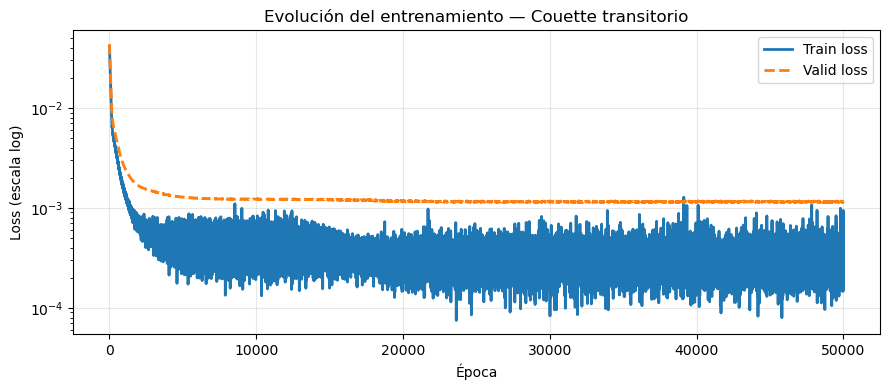

In [20]:
loss = solver.metrics_history

plt.figure(figsize=(9, 4))
plt.semilogy(loss['train_loss'], label='Train loss', linewidth=2)
plt.semilogy(loss['valid_loss'], label='Valid loss', linewidth=2, linestyle='--')
plt.xlabel('Época'); plt.ylabel('Loss (escala log)')
plt.title('Evolución del entrenamiento — Couette transitorio')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

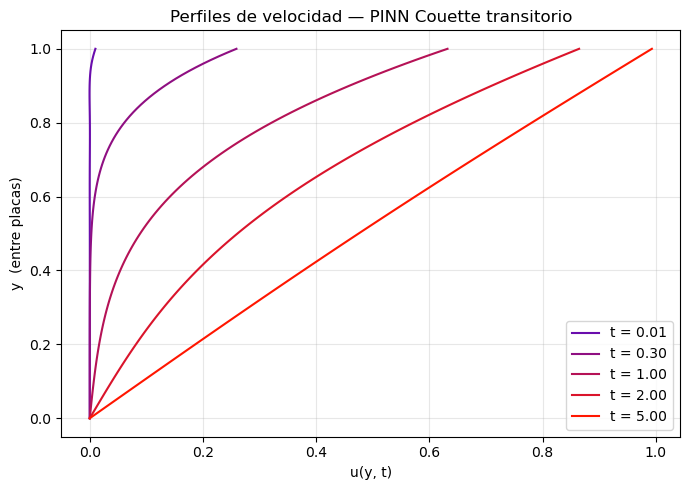

In [21]:
y_test = np.linspace(0, 1, 100)
t_vals = [0.01, 0.3, 1.0, 2.0, T_MAX]

cmap_morado_naranja = LinearSegmentedColormap.from_list('morado_rojo', ['#6A0DAD', '#ff1600'])
colors = cmap_morado_naranja(np.linspace(0, 1, len(t_vals)))

plt.figure(figsize=(7, 5))
for t_val, color in zip(t_vals, colors):
    t_arr = np.full_like(y_test, t_val)
    u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
    plt.plot(u_pred, y_test, color=color, label=f't = {t_val:.2f}')

plt.xlabel('u(y, t)')
plt.ylabel('y  (entre placas)')
plt.title('Perfiles de velocidad — PINN Couette transitorio')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

In [22]:
print(u_pred)

[0.         0.00938221 0.01876434 0.02814706 0.03753102 0.04691688
 0.05630528 0.06569684 0.0750922  0.08449196 0.09389673 0.10330712
 0.11272371 0.12214708 0.13157781 0.14101646 0.15046358 0.15991974
 0.16938545 0.17886126 0.18834767 0.19784521 0.20735438 0.21687565
 0.22640952 0.23595646 0.24551692 0.25509136 0.26468022 0.27428391
 0.28390287 0.2935375  0.30318818 0.3128553  0.32253922 0.33224032
 0.34195892 0.35169535 0.36144995 0.371223   0.38101479 0.39082561
 0.40065571 0.41050534 0.42037473 0.43026409 0.44017363 0.45010352
 0.46005395 0.47002506 0.48001698 0.49002985 0.50006376 0.51011879
 0.52019503 0.53029251 0.54041128 0.55055136 0.56071274 0.57089541
 0.58109933 0.59132445 0.6015707  0.61183799 0.62212621 0.63243524
 0.64276493 0.65311514 0.66348566 0.67387632 0.68428689 0.69471714
 0.70516682 0.71563566 0.72612338 0.73662967 0.7471542  0.75769665
 0.76825665 0.77883383 0.7894278  0.80003815 0.81066446 0.82130628
 0.83196315 0.84263461 0.85332015 0.86401928 0.87473147 0.8854

In [23]:

def couette_fd_profile(t_target, nu, tau, y_max=1.0, n_y=201):
    if t_target <= 0:
        return np.linspace(0, y_max, n_y), np.zeros(n_y)

    y  = np.linspace(0, y_max, n_y)
    dy = y[1] - y[0]
    dt = 0.4 * dy**2 / nu                       # estabilidad FTCS: r = nu*dt/dy^2 <= 0.5
    n_steps = max(1, int(np.ceil(t_target / dt)))
    dt = t_target / n_steps
    r  = nu * dt / dy**2

    u = np.zeros(n_y)
    for step in range(1, n_steps + 1):
        t = step * dt
        u_new = u.copy()
        u_new[1:-1] = u[1:-1] + r * (u[2:] - 2.0 * u[1:-1] + u[:-2])
        u_new[0]  = 0.0
        u_new[-1] = 1.0 - np.exp(-t / tau)
        u = u_new
    return y, u

print("Errores L_inf vs. solución de referencia (diferencias finitas):")
for t_val in [0.1, 0.5, 1.0, 2.0, T_MAX]:
    t_arr = np.full_like(y_test, t_val)
    u_pred       = solution(y_test, t_arr, to_numpy=True).flatten()
    y_ref, u_ref_grid = couette_fd_profile(t_val, nu, TAU_RAMP)
    u_ref        = np.interp(y_test, y_ref, u_ref_grid)
    print(f"  t = {t_val:5.2f}   max|u_pred - u_ref| = {np.max(np.abs(u_pred - u_ref)):.3e}")

# Convergencia asintótica al estacionario u(y) = y (sigue siendo válida: para t grande,
# 1 - exp(-t/tau) -> 1, así que el problema converge al mismo perfil lineal de Couette)
t_arr = np.full_like(y_test, T_MAX)
u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
print(f"\nConvergencia asintótica:  max|u(y, T_MAX) - y| = {np.max(np.abs(u_pred - y_test)):.3e}")


Errores L_inf vs. solución de referencia (diferencias finitas):
  t =  0.10   max|u_pred - u_ref| = 8.142e-04
  t =  0.50   max|u_pred - u_ref| = 2.743e-04
  t =  1.00   max|u_pred - u_ref| = 3.510e-04
  t =  2.00   max|u_pred - u_ref| = 1.310e-04
  t =  5.00   max|u_pred - u_ref| = 3.973e-04

Convergencia asintótica:  max|u(y, T_MAX) - y| = 2.526e-02


## Mapa de calor 

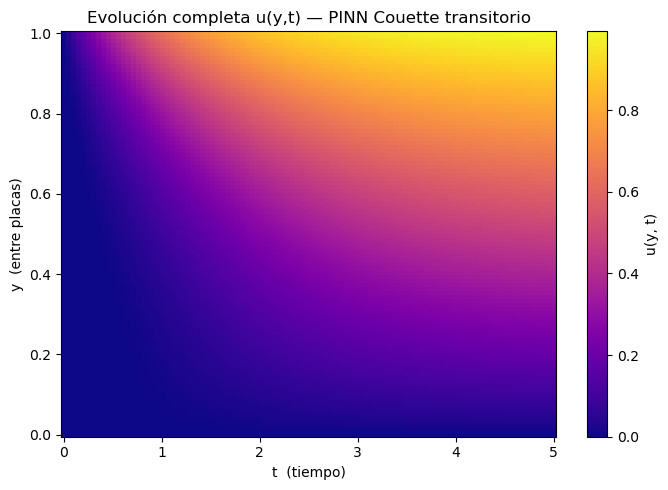

In [25]:
N_y, N_t = 100, 100
y_grid = np.linspace(0, 1, N_y)
t_grid = np.linspace(0, T_MAX, N_t)
YY, TT = np.meshgrid(y_grid, t_grid)

u_pred = solution(YY.flatten(), TT.flatten(), to_numpy=True).reshape(N_t, N_y)

plt.figure(figsize=(7, 5))
plt.pcolormesh(t_grid, y_grid, u_pred.T, cmap='plasma', shading='auto')
plt.colorbar(label='u(y, t)')
plt.xlabel('t  (tiempo)')
plt.ylabel('y  (entre placas)')
plt.title('Evolución completa u(y,t) — PINN Couette transitorio')
plt.tight_layout()
plt.show()

## RAR — Residual-based Adaptive Refinement (hard constraints)

Red entrenada desde los pesos base, añadiendo automáticamente puntos donde el residuo de la PDE es más alto. A diferencia de la versión anterior, aquí la salida se evalúa con `condition.enforce(net_rar, y, t)`, que aplica la misma reparametrización de hard constraints que el modelo base. Como la CI y las BC ya se cumplen exactamente por construcción, el loss es únicamente el residuo de la PDE — no hace falta ningún término ni peso de contorno.


In [ ]:

# ── Red y optimizador RAR (warm start desde los pesos del solver base) ────────
net_rar = FCNN(n_input_units=2, n_output_units=1, hidden_units=(32, 32), actv=nn.SiLU)
opt_rar = torch.optim.Adam(net_rar.parameters(), lr=1e-3)
DTYPE = next(net_rar.parameters()).dtype   # mismo dtype que usa neurodiffeq (float64)

# ── Hiperparámetros ───────────────────────────────────────────────────────────
N_INT        = 1000   # puntos interiores por época
RAR_INTERVAL = 100    # cada cuántas épocas añadir puntos
N_CAND       = 5000   # candidatos evaluados en cada paso RAR
N_ADD        = 50     # puntos añadidos en cada paso RAR
N_EPOCHS_RAR = 50000

pool_y = torch.zeros(0, 1, dtype=DTYPE)   # pool de puntos de alto residuo
pool_t = torch.zeros(0, 1, dtype=DTYPE)

# ── Conjunto de validación fijo (no se resamplea cada época) ──────────────────
y_valid_lin = torch.linspace(0, 1, 32, dtype=DTYPE)
t_valid_lin = torch.linspace(0, T_MAX, 32, dtype=DTYPE)
y_valid_grid, t_valid_grid = torch.meshgrid(y_valid_lin, t_valid_lin, indexing='ij')
y_valid = y_valid_grid.reshape(-1, 1)
t_valid = t_valid_grid.reshape(-1, 1)

def residuo_pde(yf, tf):
    """Calcula el residuo de la PDE en (yf, tf), usando la salida con hard constraints."""
    yf = yf.detach().requires_grad_(True)
    tf = tf.detach().requires_grad_(True)
    u    = condition.enforce(net_rar, yf, tf)            # reparametrización hard-constraint
    u_t  = torch.autograd.grad(u,   tf, grad_outputs=torch.ones_like(u),  create_graph=True)[0]
    u_y  = torch.autograd.grad(u,   yf, grad_outputs=torch.ones_like(u),  create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, yf, grad_outputs=torch.ones_like(u_y),create_graph=True)[0]
    return u_t - nu * u_yy

hist_rar = {'total': [], 'valid': []}   # train: residuo PDE en pts random+pool; valid: residuo en grid fijo

t_inicio_rar = time.time()

for epoch in range(N_EPOCHS_RAR):
    # ── RAR: buscar puntos de alto residuo y añadirlos al pool ────────────────
    if epoch > 0 and epoch % RAR_INTERVAL == 0:
        yc = torch.rand(N_CAND, 1, dtype=DTYPE)
        tc = torch.rand(N_CAND, 1, dtype=DTYPE) * T_MAX
        res = residuo_pde(yc, tc).abs().detach().squeeze()
        idx = torch.topk(res, N_ADD).indices
        pool_y = torch.cat([pool_y, yc[idx].detach()])
        pool_t = torch.cat([pool_t, tc[idx].detach()])

    # ── Loss: solo el residuo de la PDE (puntos uniformes + pool) ─────────────
    yf = torch.cat([torch.rand(N_INT, 1, dtype=DTYPE), pool_y])
    tf = torch.cat([torch.rand(N_INT, 1, dtype=DTYPE) * T_MAX, pool_t])
    loss = residuo_pde(yf, tf).pow(2).mean()

    opt_rar.zero_grad()
    loss.backward()
    opt_rar.step()

    hist_rar['total'].append(loss.item())

    # ── Validación: mismo residuo, evaluado en el grid fijo (sin actualizar pesos) ─
    loss_valid = residuo_pde(y_valid, t_valid).pow(2).mean()
    hist_rar['valid'].append(loss_valid.item())

    if epoch % 500 == 0:
        print(f"Época {epoch:5d} | PDE={loss.item():.3e} | valid={loss_valid.item():.3e} | pool={pool_y.shape[0]} pts")

t_fin_rar = time.time()

print(f"\nRAR completado. Pool final: {pool_y.shape[0]} puntos.")
print(f"Tiempo de entrenamiento RAR: {t_fin_rar - t_inicio_rar:.2f} s ({(t_fin_rar - t_inicio_rar)/60:.2f} min)")

def solution_rar(y_np, t_np):
    """Evalúa la solución RAR, aplicando la misma reparametrización hard-constraint que el modelo base."""
    y_t = torch.tensor(np.asarray(y_np).flatten(), dtype=DTYPE).reshape(-1, 1)
    t_t = torch.tensor(np.asarray(t_np).flatten(), dtype=DTYPE).reshape(-1, 1)
    with torch.no_grad():
        return condition.enforce(net_rar, y_t, t_t).numpy().flatten()

# ── Curva de pérdida del RAR ───────────────────────────────────────────────────
plt.figure(figsize=(9, 4))
plt.semilogy(hist_rar['total'], label='RAR — train (residuo PDE)', linewidth=2)
plt.semilogy(hist_rar['valid'], label='RAR — valid (grid fijo)', linewidth=2, linestyle='--')
plt.xlabel('Época'); plt.ylabel('Loss (escala log)')
plt.title('Evolución del entrenamiento — RAR (hard constraints)')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


Época     0 | PDE=3.701e-02 | valid=4.021e-02 | pool=0 pts
Época   500 | PDE=1.314e-02 | valid=3.677e-03 | pool=250 pts
Época  1000 | PDE=6.700e-03 | valid=1.798e-03 | pool=500 pts
Época  1500 | PDE=4.135e-03 | valid=1.468e-03 | pool=750 pts
Época  2000 | PDE=2.915e-03 | valid=1.312e-03 | pool=1000 pts
Época  2500 | PDE=1.856e-03 | valid=1.235e-03 | pool=1250 pts
Época  3000 | PDE=1.635e-03 | valid=1.185e-03 | pool=1500 pts
Época  3500 | PDE=1.306e-03 | valid=1.133e-03 | pool=1750 pts
Época  4000 | PDE=1.078e-03 | valid=1.104e-03 | pool=2000 pts
Época  4500 | PDE=8.121e-04 | valid=1.085e-03 | pool=2250 pts
Época  5000 | PDE=8.425e-04 | valid=1.073e-03 | pool=2500 pts
Época  5500 | PDE=7.153e-04 | valid=1.073e-03 | pool=2750 pts
Época  6000 | PDE=5.919e-04 | valid=1.055e-03 | pool=3000 pts
Época  6500 | PDE=5.191e-04 | valid=1.051e-03 | pool=3250 pts
Época  7000 | PDE=4.391e-04 | valid=1.046e-03 | pool=3500 pts
Época  7500 | PDE=4.493e-04 | valid=1.043e-03 | pool=3750 pts
Época  8000 | 

## Comparación de errores: Base vs RAR


     t    Error base     Error RAR      Mejora
------------------------------------------------
  0.10     8.142e-04     4.337e-05      +94.7%
  0.50     2.743e-04     9.412e-05      +65.7%
  1.00     3.510e-04     1.203e-04      +65.7%
  2.00     1.310e-04     2.660e-04     -103.0%
  5.00     3.973e-04     2.826e-04      +28.9%


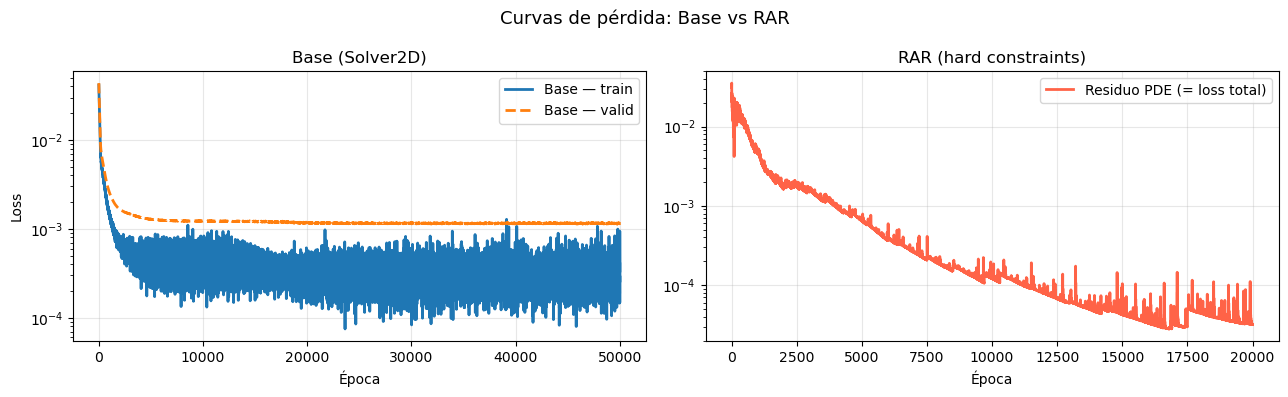

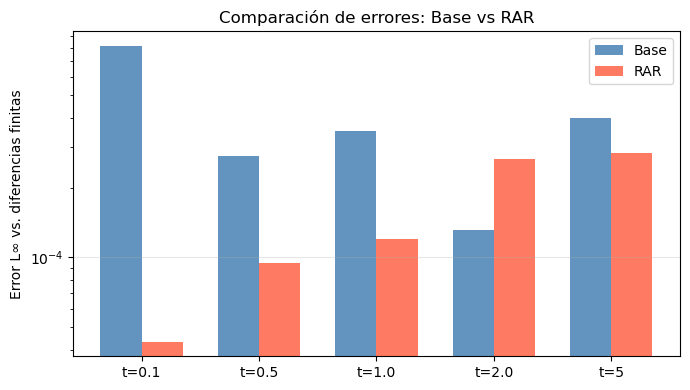

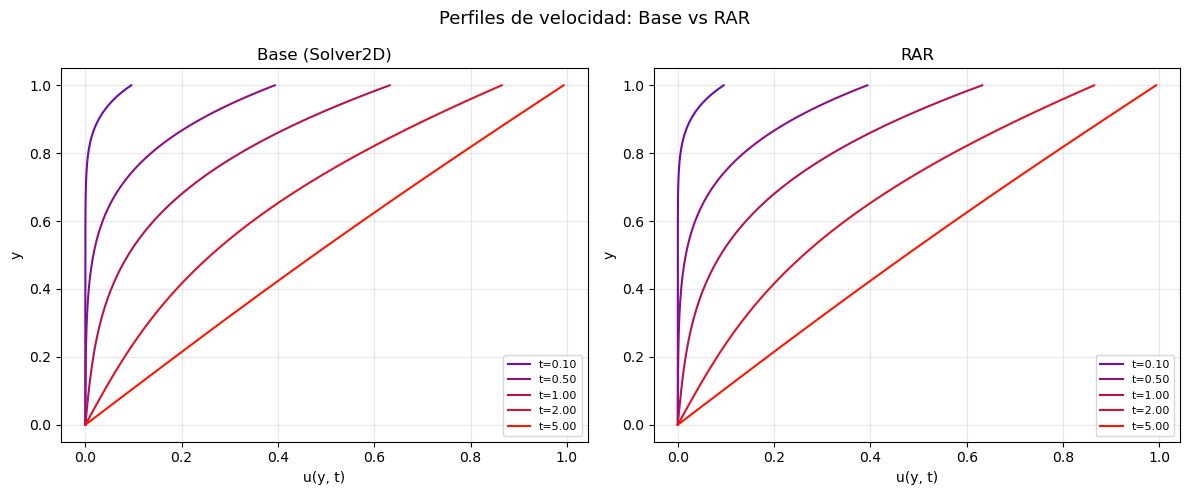

In [59]:
# ── Comparación de errores: Base vs RAR ──────────────────────────────────────
t_vals = [0.1, 0.5, 1.0, 2.0, T_MAX]
y_test = np.linspace(0, 1, 100)

err_base, err_rar = [], []

print(f"{'t':>6}  {'Error base':>12}  {'Error RAR':>12}  {'Mejora':>10}")
print("-" * 48)
for t_val in t_vals:
    t_arr = np.full_like(y_test, t_val)

    u_base = solution(y_test, t_arr, to_numpy=True).flatten()
    u_rar_ = solution_rar(y_test, t_arr)

    _, u_ref = couette_fd_profile(t_val, nu, TAU_RAMP)
    u_ref_interp = np.interp(y_test, np.linspace(0, 1, len(u_ref)), u_ref)

    e_base = np.max(np.abs(u_base - u_ref_interp))
    e_rar  = np.max(np.abs(u_rar_  - u_ref_interp))
    mejora = (e_base - e_rar) / e_base * 100

    err_base.append(e_base)
    err_rar.append(e_rar)
    print(f"{t_val:>6.2f}  {e_base:>12.3e}  {e_rar:>12.3e}  {mejora:>+9.1f}%")

# ── Gráfica de curvas de pérdida ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

lh = solver.metrics_history
axes[0].semilogy(lh['train_loss'], label='Base — train', linewidth=2)
axes[0].semilogy(lh['valid_loss'], label='Base — valid', linewidth=2, linestyle='--')
axes[0].set_title('Base (Solver2D)'); axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].semilogy(hist_rar['total'], label='Residuo PDE (= loss total)', linewidth=2, color='tomato')
axes[1].set_title('RAR (hard constraints)'); axes[1].set_xlabel('Época')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Curvas de pérdida: Base vs RAR', fontsize=13)
plt.tight_layout(); plt.show()

# ── Gráfica de errores por instante de tiempo ─────────────────────────────────
plt.figure(figsize=(7, 4))
x = np.arange(len(t_vals))
w = 0.35
plt.bar(x - w/2, err_base, w, label='Base',  color='steelblue', alpha=0.85)
plt.bar(x + w/2, err_rar,  w, label='RAR',   color='tomato',    alpha=0.85)
plt.yscale('log')
plt.xticks(x, [f't={t}' for t in t_vals])
plt.ylabel('Error L∞ vs. diferencias finitas')
plt.title('Comparación de errores: Base vs RAR')
plt.legend(); plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

# ── Perfiles de velocidad comparados ─────────────────────────────────────────
cmap_morado_rojo = LinearSegmentedColormap.from_list('morado_rojo', ['#6A0DAD', '#ff1600'])
colors = cmap_morado_rojo(np.linspace(0, 1, len(t_vals)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, sol, title in zip(axes,
                           [lambda y,t: solution(y, t, to_numpy=True).flatten(), solution_rar],
                           ['Base (Solver2D)', 'RAR']):
    for t_val, color in zip(t_vals, colors):
        t_arr  = np.full_like(y_test, t_val)
        ax.plot(sol(y_test, t_arr), y_test, label=f't={t_val:.2f}', color=color)
    ax.set_xlabel('u(y, t)'); ax.set_ylabel('y')
    ax.set_title(title); ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.suptitle('Perfiles de velocidad: Base vs RAR', fontsize=13)
plt.tight_layout(); plt.show()

## Comparación directa de las curvas de pérdida (Base vs RAR)


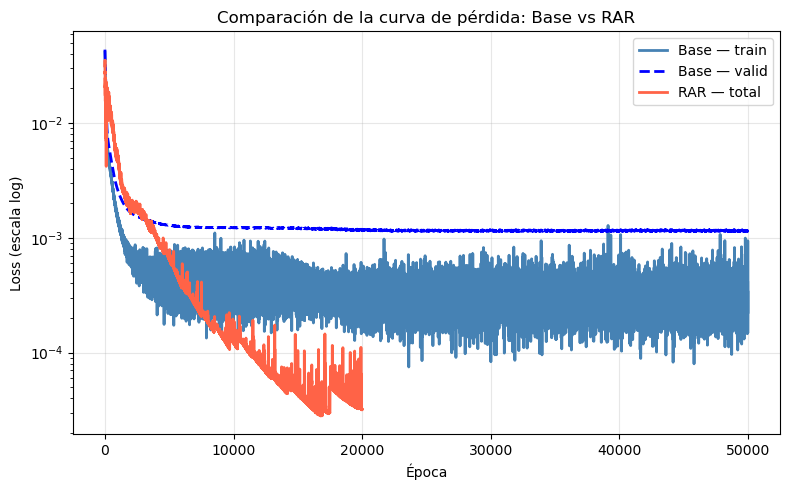

In [65]:
# ── Loss Base vs Loss RAR, superpuestas en la misma gráfica ──────────────────
plt.figure(figsize=(8, 5))
plt.semilogy(lh['train_loss'], label='Base — train', linewidth=2, color='steelblue')
plt.semilogy(lh['valid_loss'], label='Base — valid', linewidth=2, color='blue', linestyle='--')
plt.semilogy(hist_rar['total'], label='RAR — total', linewidth=2, color='tomato')

plt.xlabel('Época')
plt.ylabel('Loss (escala log)')
plt.title('Comparación de la curva de pérdida: Base vs RAR')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()